# Home Assignment 3: 3 Sleep Well

## Set up Python

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import pandas as pd
import jinja2

# Import sklearn functions
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import SGDClassifier 
from sklearn.metrics import zero_one_loss
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.neighbors import KNeighborsClassifier

# Costum plots
plt.style.use(['science'])
plt.rcParams["figure.figsize"] = (14/2.54, 8.4/2.54)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9
plt.rcParams["legend.fontsize"] = 9

# Set output directory
output_dir = "output/"

## Load data

In [3]:
x_train = np.genfromtxt(r'data/X_train.csv', delimiter=',')
y_train = np.genfromtxt(r'data/y_train.csv', delimiter=',')
x_test = np.genfromtxt(r'data/X_test.csv', delimiter=',')
y_test = np.genfromtxt(r'data/y_test.csv', delimiter=',')

print(f'Shape of y_train: {y_train.shape}')
print(f'Shape of x_train: {x_train.shape}')
print(f'Classes in y_train: {np.unique(y_train)}')

Shape of y_train: (33724,)
Shape of x_train: (33724, 16)
Classes in y_train: [0. 1. 2. 3. 4.]


## 0. Class frequencies

In [4]:
# Classes observed in the training data and the number of points in each
classes, class_counts = np.unique(y_train, return_counts=True)

# Class frequencies = count per class / total number of training points
class_frequencies = class_counts / class_counts.sum()

# Sum of frequencies should be 1
assert np.isclose(class_frequencies.sum(), 1), 'Frequencies do not sum to 1'

# Build pandas dataframe
table = pd.DataFrame({
    'Class': classes.astype(int).astype(str),
    'Count': class_counts.astype(int),
    'Frequency': class_frequencies,
})

# Create total row and append
total_row = pd.DataFrame({
    'Class': ['Total:'],
    'Count': [int(table['Count'].sum())],
    'Frequency': [table['Frequency'].sum()],
})
table = pd.concat([table, total_row], ignore_index=True)

# Create latex table
print(table.to_latex(index=False, float_format='%.3f'))


\begin{tabular}{lrr}
\toprule
Class & Count & Frequency \\
\midrule
0 & 17566 & 0.521 \\
1 & 3221 & 0.096 \\
2 & 8523 & 0.253 \\
3 & 1583 & 0.047 \\
4 & 2831 & 0.084 \\
Total: & 33724 & 1.000 \\
\bottomrule
\end{tabular}



## 1. Logistic regression

In [15]:
lr_model = SGDClassifier(
    loss='log_loss',   # logistic regression loss
    tol=1e-8,
    penalty=None,
    max_iter=1000,
    random_state=8008,
)

# Train model
lr_model.fit(x_train, y_train)

# Calculate predictions using trained model
y_pred_train = lr_model.predict(x_train)
y_pred_test = lr_model.predict(x_test)

# Calculate training and test errors
train_error = zero_one_loss(y_train, y_pred_train)
test_error = zero_one_loss(y_test, y_pred_test)

# Print results
print(f'Number of iterations: {lr_model.n_iter_}')
print(f'Training errors (0-1 loss): {train_error}')
print(f'Test errors (0-1 loss): {test_error}')


Number of iterations: 90
Training errors (0-1 loss): 0.1521468390463765
Test errors (0-1 loss): 0.09675562909143232


## 2. Random forest

In [30]:
# Number of trees in each forest
n_trees = np.array([50, 100, 200])

# Create grids for output
loss_train_grid = np.zeros(len(n_trees))
loss_test_grid = np.zeros(len(n_trees))
OOB_grid = np.zeros(len(n_trees))

# Run ML, Loop over forests
for idx, B in enumerate(n_trees):

    # Model selection
    model_rf = RandomForestClassifier(
        n_estimators=B, # Number of decision trees
        max_features='sqrt', # maximum variables considered per split m=(\sqrt{D}) 
        criterion='gini', # Impurity measure
        min_samples_split=5, # The minimum number of samples a node must have before it's allowed to split further
        oob_score=True, # Compute an out-of-bag (OOB) score
        random_state=8008, # Random generator seed
    )

    # Train model
    model_rf.fit(x_train, y_train)

    # Calculate predictions using trained model
    y_pred_train = model_rf.predict(x_train)
    y_pred_test = model_rf.predict(x_test)

    # Calculate OOB, training and test loss (0-1 loss)
    OOB_grid[idx] = model_rf.oob_score_
    loss_train_grid[idx] = zero_one_loss(y_train, y_pred_train)
    loss_test_grid[idx] = zero_one_loss(y_test, y_pred_test)

In [ ]:
# Build pandas dataframe with results
random_forest_table = pd.DataFrame({
    'Number of trees (B)': n_trees.astype(int),
    'OOB error': OOB_grid,
    'Train loss (0--1)': loss_train_grid,
    'Test loss(0--1)': loss_test_grid,
})

# Create latex table
print(random_forest_table.to_latex(index=False, float_format='%.4f'))

\begin{tabular}{rrrr}
\toprule
Number of trees (B) & OOB & 0-1 loss (train) & 0-1 loss (test) \\
\midrule
50 & 0.8465 & 0.0080 & 0.1131 \\
100 & 0.8508 & 0.0063 & 0.1122 \\
200 & 0.8534 & 0.0050 & 0.1098 \\
\bottomrule
\end{tabular}



## 3. Nearest neighbor

In [8]:
# Select maximum k and number of folds
k_max = 100
n_folds = 5

# Define possible classes
class_labels = np.unique(y_train).astype(int)

# generate fold indexes (stratified, same folds for every k)
kf = StratifiedKFold(
    n_splits=n_folds, shuffle=True, random_state=999
    )

# fold_errors[fold, k]
fold_errors = np.zeros((n_folds, k_max))

for fold, (train_idx, val_idx) in enumerate(kf.split(x_train, y_train)):
    X_tr, y_tr = x_train[train_idx], y_train[train_idx]
    X_val, y_val = x_train[val_idx], y_train[val_idx]

    # Model selection and training
    nn = NearestNeighbors(n_neighbors=k_max, metric='minkowski', p=2)
    nn.fit(X_tr)

    # Retrieve ordered indexes of distance from nearest to farthest neighbor
    idx = nn.kneighbors(X_val, return_distance=False)

    # Replace indexes by classes
    nn_labels = y_tr[idx]

    # Majority vote for each k
    for k in range(1, k_max+1):
        # Count votes per class for each validation point: (n_val, n_classes)
        counts = (nn_labels[:, :k, None] == class_labels[None, None, :]).sum(axis=1)
        preds = counts.argmax(axis=1)
        fold_errors[fold, k-1] = zero_one_loss(y_val, preds)

# Average over folds -> mean CV error for each k
errors = fold_errors.mean(axis=0)

# Calculate k with minimum errors
k_with_min_error = np.argmin(errors)+1
k_min_error = np.min(errors)

Number of nearest neighbors with minimum errors: 60
Mean 0-1 loss with K=60: 0.14935941741477146


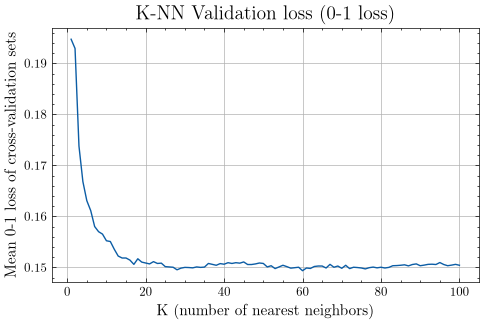

In [9]:
# Print results and plot mean errors as a function of k
print(f'Number of nearest neighbors with minimum errors: {k_with_min_error}')
print(f'Mean 0-1 loss with K={k_with_min_error}: {k_min_error}')

plt.plot(range(1, k_max+1), errors)
plt.xlabel("K (number of nearest neighbors)")
plt.ylabel("Mean 0-1 loss of cross-validation sets")
plt.title("K-NN Validation loss (0-1 loss)")
plt.grid(True)

filename = "K-NN_Validation_Errors.png"
plt.savefig(output_dir + filename, dpi=300, bbox_inches="tight")
# plt.close()

In [10]:
# Model selection with k = 100
model_knn = KNeighborsClassifier(
    n_neighbors=60,  # Number of neighbors to use for classification
    weights='uniform',  # 'uniform' or 'distance'
    metric='minkowski',  # Distance metric (minkowski = Euclidean when p=2)
    p=2,  # Power parameter for the minkowski metric
)

# Train model
model_knn.fit(x_train, y_train)

# Calculate predictions using trained model
y_pred_train = model_knn.predict(x_train)
y_pred_test = model_knn.predict(x_test)

# Calculate training and test errors (0-1 loss)
train_error = zero_one_loss(y_train, y_pred_train)
test_error = zero_one_loss(y_test, y_pred_test)

# Print results
print(f'Training errors (0-1 loss): {train_error}')
print(f'Test errors (0-1 loss): {test_error}')

Training errors (0-1 loss): 0.1462163444431266
Test errors (0-1 loss): 0.09797856269333138
